# 04 · Reinforcement Learning: Learning from Rewards

In notebooks 01 to 03 somebody handed the network the right answer for every example (**supervised learning**). Many problems do not work like that. Nobody can write down the correct move for every position of a game, the correct torque for every instant of a balancing robot, or the correct turbine set-point for every wind condition. What we *can* do is say afterwards **how well it went**. **Reinforcement learning** (RL) is learning to act from that kind of delayed, scalar feedback.

In this notebook you will build, in plain NumPy and a little PyTorch, and run on a laptop CPU:

1. the vocabulary of RL and a measured look at the **exploration / exploitation** trade-off with multi-armed bandits (epsilon-greedy and UCB (upper confidence bound));
2. **tabular Q-learning** on a gridworld with a cliff, with learning curves and the learned policy, compared with its cousin SARSA (state, action, reward, state, action);
3. **policy gradient** (REINFORCE) on a cart-pole balancing task that we implement ourselves, and a measurement of its **variance** with and without a baseline;
4. an **actor-critic** step and the clipped **PPO** (proximal policy optimisation) objective, compared with REINFORCE on the same task;
5. a **reward-hacking** toy: an agent that earns a high reward by doing the wrong thing;
6. a clearly labelled **preview** of how the same ideas train language models (RLHF, reinforcement learning from human feedback), built for real in module 01 of Neural Networks 1002.

**Contents**

1. The vocabulary of reinforcement learning
2. Bandits: exploration versus exploitation
3. Q-learning on a cliff gridworld
4. Policy gradient: REINFORCE on cart-pole
5. Actor-critic and PPO
6. Reward hacking
7. Preview: from games to language models
8. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [01 The neuron](01_the_neuron.ipynb) | a unit that turns inputs into an output, gradient descent |
| [02 Neural network and backprop](02_neural_network_backprop.ipynb) | backpropagation, which PyTorch autograd does for us in sections 4 and 5 |
| [03 Training deep networks](03_training_deep_networks.ipynb) | Adam, learning rates, why noisy gradients make training harder |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it. Everything runs in a few minutes on a CPU, with fixed random seeds. All environments are written here in NumPy, so there is no dependency on a game library and no download.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks/04_reinforcement_learning.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). The times shown in this notebook were measured on a multi-core machine; a free Colab CPU runtime (about 2 cores) can take several times longer.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

## 1. The vocabulary of reinforcement learning

An **agent** interacts with an **environment** in a loop. At each time step $t$ the agent sees a **state** $s_t$ (what it can observe), chooses an **action** $a_t$, and the environment answers with a **reward** $r_{t+1}$ (a single number) and a new state $s_{t+1}$.

| Term | Meaning | Cart-pole example |
|---|---|---|
| state $s$ | what the agent observes | cart position, cart velocity, pole angle, pole angular velocity |
| action $a$ | what it can do | push the cart left or right |
| reward $r$ | scalar feedback | +1 for every step the pole is still up |
| **policy** $\pi(a \mid s)$ | the rule that picks actions: the probability of action $a$ in state $s$ | a small neural network |
| **return** $G_t$ | total future reward from time $t$ | $G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots$ |
| **discount** $\gamma \in [0,1]$ | how much a reward $k$ steps away is worth: $\gamma^k$ | $\gamma = 0.99$: a reward 100 steps away counts about 37 % |
| value $V^\pi(s)$ | expected return from $s$ if we follow $\pi$ | "how good is this position" |
| action value $Q^\pi(s,a)$ | expected return after taking $a$ in $s$, then following $\pi$ | "how good is this move" |

The goal is a policy that maximises the expected return. Two things make RL harder than supervised learning:

* **Credit assignment.** The reward arrives late. Which of the last 200 pushes caused the pole to fall? The return $G_t$ spreads the credit backwards in time.
* **The data depends on the agent.** What the agent sees next depends on what it chose. If it never tries an action it never learns what that action is worth. That is the exploration problem, which we meet first in its purest form.

Two families of methods appear in this notebook: **value-based** (learn $Q(s,a)$, act greedily on it: section 3) and **policy-based** (adjust the policy directly: sections 4 and 5). The classic reference is Sutton and Barto (2018), free online, see the references at the end.

## 2. Bandits: exploration versus exploitation

The simplest RL problem has **no states**. A **multi-armed bandit** is a row of $K$ slot machines. Each arm $a$ pays a random reward with an unknown mean $q_*(a)$. Pulling an arm gives a reward and nothing else. The agent must decide: pull the arm that looks best so far (**exploit**), or try another arm to learn whether it is better (**explore**)?

We use a 10-armed bandit. For each run the true means are drawn from a normal distribution with mean 0 and standard deviation 1 (written $\mathcal{N}(0,1)$), and a pull of arm $a$ returns a reward drawn from $\mathcal{N}(q_*(a), 1)$. We estimate each arm's value by the **sample average** of its rewards, $Q_t(a)$, and compare three rules:

* **greedy** ($\varepsilon = 0$): always pull $\arg\max_a Q_t(a)$;
* **epsilon-greedy**: with probability $\varepsilon$ pull a random arm, otherwise the greedy one;
* **UCB** (upper confidence bound, Auer et al. 2002): pull $\arg\max_a \left[ Q_t(a) + c \sqrt{\ln t / N_t(a)} \right]$, where $N_t(a)$ is how often arm $a$ has been pulled and $c$ sets how strongly uncertainty is rewarded. Rarely pulled arms get a large bonus, so exploration is directed at the arms we know least about.

We average over 1000 independent bandit problems so the curves are smooth.

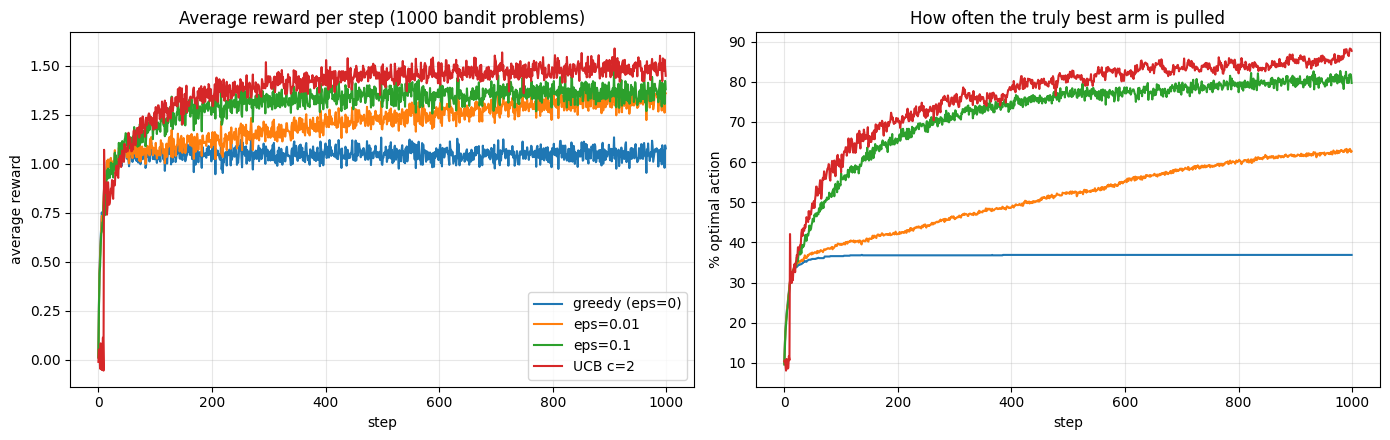

method            mean reward, steps 1-1000    mean reward, last 100   % optimal, last 100
greedy (eps=0)                        1.041                    1.050                  36.9
eps=0.01                              1.207                    1.325                  62.2
eps=0.1                               1.305                    1.362                  80.4
UCB c=2                               1.389                    1.485                  85.7
(4.3 s)


In [2]:
K, STEPS, RUNS = 10, 1000, 1000

def run_bandit(method, param, seed=0):
    rng = np.random.default_rng(seed)
    q_true = rng.normal(0, 1, (RUNS, K))
    best = q_true.argmax(1)
    Q = np.zeros((RUNS, K)); N = np.zeros((RUNS, K))
    rows = np.arange(RUNS)
    reward_curve, optimal_curve = np.zeros(STEPS), np.zeros(STEPS)
    for t in range(1, STEPS + 1):
        if method == "ucb":
            with np.errstate(divide="ignore", invalid="ignore"):
                bonus = np.where(N == 0, np.inf, param * np.sqrt(np.log(t) / N))
            score = Q + bonus
        else:
            score = Q + rng.uniform(0, 1e-9, Q.shape)             # random tie-breaking
        a = score.argmax(1)
        if method == "eps":
            explore = rng.random(RUNS) < param
            a = np.where(explore, rng.integers(0, K, RUNS), a)
        r = rng.normal(q_true[rows, a], 1.0)
        N[rows, a] += 1
        Q[rows, a] += (r - Q[rows, a]) / N[rows, a]              # incremental sample average
        reward_curve[t - 1] = r.mean()
        optimal_curve[t - 1] = (a == best).mean()
    return reward_curve, optimal_curve

configs = [("greedy (eps=0)", "eps", 0.0), ("eps=0.01", "eps", 0.01), ("eps=0.1", "eps", 0.1), ("UCB c=2", "ucb", 2.0)]
t0 = time.time()
bandit_res = {name: run_bandit(m, p) for name, m, p in configs}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (rc, oc) in bandit_res.items():
    axes[0].plot(rc, label=name); axes[1].plot(100 * oc, label=name)
axes[0].set_title("Average reward per step (1000 bandit problems)"); axes[0].set_xlabel("step"); axes[0].set_ylabel("average reward")
axes[1].set_title("How often the truly best arm is pulled"); axes[1].set_xlabel("step"); axes[1].set_ylabel("% optimal action")
axes[0].legend(); plt.tight_layout(); plt.show()

print(f"{'method':16s} {'mean reward, steps 1-1000':>26s} {'mean reward, last 100':>24s} {'% optimal, last 100':>21s}")
for name, (rc, oc) in bandit_res.items():
    print(f"{name:16s} {rc.mean():26.3f} {rc[-100:].mean():24.3f} {100*oc[-100:].mean():21.1f}")
print(f"({time.time()-t0:.1f} s)")

**Reading.** The greedy agent locks onto the first arm that looked decent and rarely finds the best one: it is fast early and flat later. Exploring a little ($\varepsilon = 0.1$) climbs more slowly at first but ends clearly higher, because it keeps sampling and eventually identifies the best arm. A smaller $\varepsilon$ explores less and is slower to find it, so within 1000 steps it sits between greedy and 0.1 (more steps would favour it). UCB is the best of the four here in the late steps, because its exploration is *directed*: it stops pulling arms it is already sure are bad. The exact numbers depend on the problem distribution (UCB is sensitive to $c$, and with other reward distributions epsilon-greedy can win), so read this as an illustration of the trade-off, not as a ranking of algorithms. Even the best method never reaches 100 % optimal pulls: the rewards are noisy and the means of the top arms are close.

## 3. Q-learning on a cliff gridworld

Now we add **states** and **delayed consequences**. The classic cliff-walking task (Sutton and Barto, 2018, example 6.6) is a 4 × 12 grid. The agent starts at the bottom-left, the goal is the bottom-right, and the bottom row between them is a **cliff**. Every step costs $-1$ (so shorter paths are better). Stepping into the cliff costs $-100$ and sends the agent back to the start. The short path runs right along the cliff edge. The long path goes along the top and is safe.

**Q-learning** (Watkins and Dayan, 1992) keeps a table $Q(s,a)$ and, after every step $(s, a, r, s')$, moves it towards a better estimate:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \Big]$$

Here $\alpha$ is the learning rate and the term in brackets is the **temporal-difference (TD) error**: the difference between what happened (the reward plus our estimate of the best continuation) and what we predicted. The agent follows an **epsilon-greedy** policy while learning ($\varepsilon = 0.1$), the same exploration rule as in section 2. **SARSA** is identical except that it uses the action $a'$ it *actually takes next* instead of the max, so it learns the value of the exploring policy itself. Q-learning is **off-policy** (it learns about the greedy policy while behaving differently), SARSA is **on-policy**.

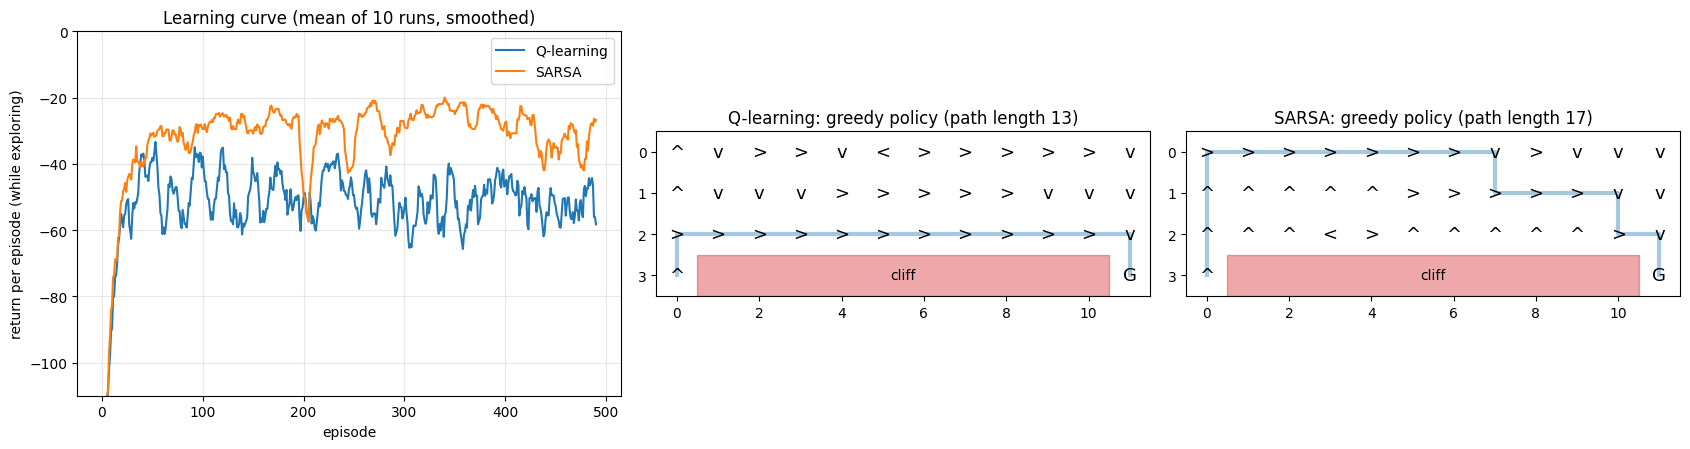

mean return per episode during training, last 100 episodes: Q-learning -51.9, SARSA -31.5
greedy path length, seed 0: Q-learning 13 steps, SARSA 17 steps (shortest possible: 13)
(10.9 s)


In [3]:
ROWS, COLS = 4, 12
START, GOAL = (3, 0), (3, 11)
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # up, right, down, left
ARROWS = ["^", ">", "v", "<"]

def grid_step(s, a):
    r, c = s[0] + MOVES[a][0], s[1] + MOVES[a][1]
    r, c = min(max(r, 0), ROWS - 1), min(max(c, 0), COLS - 1)
    if r == 3 and 1 <= c <= 10:                      # the cliff
        return START, -100.0, False
    return (r, c), -1.0, (r, c) == GOAL

def train_grid(algo, seed, episodes=500, alpha=0.5, gamma=1.0, eps=0.1):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS, COLS, 4))
    pick = lambda s: int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[s] + rng.uniform(0, 1e-9, 4)))
    returns = []
    for ep in range(episodes):
        s, a, total, done, steps = START, None, 0.0, False, 0
        a = pick(s)
        while not done and steps < 500:
            s2, r, done = grid_step(s, a)
            a2 = pick(s2)
            target = r + (0.0 if done else gamma * (Q[s2].max() if algo == "q" else Q[s2][a2]))
            Q[s][a] += alpha * (target - Q[s][a])
            s, a, total, steps = s2, a2, total + r, steps + 1
        returns.append(total)
    return Q, np.array(returns)

t0 = time.time()
res = {algo: [train_grid(algo, seed) for seed in range(10)] for algo in ["q", "sarsa"]}
curves = {algo: np.mean([r for _, r in res[algo]], axis=0) for algo in res}
smooth = lambda x, k=10: np.convolve(x, np.ones(k) / k, mode="valid")

def greedy_path(Q):
    s, path = START, [START]
    for _ in range(60):
        s, _, done = grid_step(s, int(np.argmax(Q[s])))
        path.append(s)
        if done: break
    return path

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
axes[0].plot(smooth(curves["q"]), label="Q-learning"); axes[0].plot(smooth(curves["sarsa"]), label="SARSA")
axes[0].set_ylim(-110, 0); axes[0].set_xlabel("episode"); axes[0].set_ylabel("return per episode (while exploring)")
axes[0].set_title("Learning curve (mean of 10 runs, smoothed)"); axes[0].legend()
for ax, (algo, title) in zip(axes[1:], [("q", "Q-learning: greedy policy"), ("sarsa", "SARSA: greedy policy")]):
    Q = res[algo][0][0]                                   # run with seed 0
    ax.set_xlim(-0.5, COLS - 0.5); ax.set_ylim(ROWS - 0.5, -0.5); ax.set_aspect("equal"); ax.grid(False)
    ax.add_patch(plt.Rectangle((0.5, 2.5), 10, 1, color="tab:red", alpha=0.4)); ax.text(5.5, 3, "cliff", ha="center", va="center")
    path = greedy_path(Q)
    ax.plot([p[1] for p in path], [p[0] for p in path], color="tab:blue", lw=3, alpha=0.4)
    for r in range(ROWS):
        for c in range(COLS):
            if r == 3 and 1 <= c <= 10: continue
            ax.text(c, r, "G" if (r, c) == GOAL else ARROWS[int(np.argmax(Q[r, c]))], ha="center", va="center", fontsize=13)
    ax.set_title(title + f" (path length {len(path)-1})")
plt.tight_layout(); plt.show()

last = {a: curves[a][-100:].mean() for a in curves}
print(f"mean return per episode during training, last 100 episodes: Q-learning {last['q']:.1f}, SARSA {last['sarsa']:.1f}")
print(f"greedy path length, seed 0: Q-learning {len(greedy_path(res['q'][0][0]))-1} steps, SARSA {len(greedy_path(res['sarsa'][0][0]))-1} steps (shortest possible: 13)")
print(f"({time.time()-t0:.1f} s)")

**Reading.** Both agents learn: the return starts near $-100$ or worse (it falls off the cliff while exploring) and climbs steadily. The two policies differ in a way that is the whole point of the example. Q-learning learns the values of the *optimal greedy* policy, which hugs the cliff edge (the shortest path). But while learning it still takes random actions 10 % of the time, and next to a cliff a random step is expensive, so its *training-time* return is lower than SARSA's. SARSA learns the value of the policy it is really executing, random steps included, and therefore prefers the longer, safer route. Neither is "wrong": they optimise different things. If the agent will behave greedily after training, Q-learning's path is better. If exploration must stay on (or mistakes are costly), SARSA's caution pays. (In your own run the exact path can differ by a few cells, since 500 episodes of a noisy table are not fully converged.)

**Where this stops working.** A table needs one entry per (state, action). A 4 × 12 grid has 48 states. A game of Go has about $10^{170}$. The fix is to replace the table with a neural network $Q_\theta(s,a)$, which is what deep Q-networks do (Mnih et al., 2015), or to learn the policy directly, which we do next.

## 4. Policy gradient: REINFORCE on cart-pole

Instead of learning values and acting greedily, **policy-gradient** methods parametrise the policy itself, $\pi_\theta(a \mid s)$, as a neural network with weights $\theta$, and do gradient ascent on the expected return $J(\theta)$. The **policy gradient theorem** gives the gradient as an expectation we can estimate from sampled episodes:

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[ \sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\; G_t \Big]$$

In words: raise the log-probability of each action taken, in proportion to the return that followed it. Good outcomes make their actions more likely, bad outcomes less. The estimator that does exactly this with sampled episodes is **REINFORCE** (Williams, 1992). In code we minimise the "loss" $-\sum_t \log\pi_\theta(a_t|s_t)\, G_t$, and autograd produces the gradient.

**The task.** We implement the classic **cart-pole** (Barto, Sutton and Anderson, 1983) ourselves: a pole hinged on a cart that slides on a track. The agent pushes the cart left or right with a fixed force every 0.02 s. The state is $(x, \dot x, \theta, \dot\theta)$ (cart position, cart velocity, pole angle, pole angular velocity). The reward is $+1$ for every step the pole stays within 12 degrees of upright and the cart within 2.4 units of the centre. An episode is capped at 200 steps, so **200 is the best possible score**. The environment below is vectorised over many simultaneous copies so that we can run 16 episodes at once.

In [4]:
class CartPole:
    # classic cart-pole physics, Euler integration, vectorised over n independent copies
    g, mc, mp, l, force, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, n, rng): self.n, self.rng = n, rng
    def reset(self):
        self.x = self.rng.uniform(-0.05, 0.05, (self.n, 4))
        return self.x.copy()
    def step(self, a):
        x, xd, th, thd = self.x.T
        f = np.where(a == 1, self.force, -self.force)
        c, s = np.cos(th), np.sin(th); tm = self.mc + self.mp; pl = self.mp * self.l
        tmp = (f + pl * thd ** 2 * s) / tm
        tha = (self.g * s - c * tmp) / (self.l * (4 / 3 - self.mp * c ** 2 / tm))
        xa = tmp - pl * tha * c / tm
        self.x = np.stack([x + self.tau * xd, xd + self.tau * xa, th + self.tau * thd, thd + self.tau * tha], 1)
        done = (np.abs(self.x[:, 0]) > 2.4) | (np.abs(self.x[:, 2]) > 0.2095)
        return self.x.copy(), done

HORIZON, GAMMA = 200, 0.99
def mlp(out): return nn.Sequential(nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, out))

def rollout(policy, n, rng):
    # run n episodes in parallel; M[t, i] = 1 while episode i is still running at step t (that step earns reward +1)
    env = CartPole(n, rng); s = env.reset(); alive = np.ones(n, bool)
    S = np.zeros((HORIZON, n, 4), np.float32); A = np.zeros((HORIZON, n), np.int64); M = np.zeros((HORIZON, n), np.float32)
    for t in range(HORIZON):
        S[t], M[t] = s, alive
        with torch.no_grad():
            a = torch.distributions.Categorical(logits=policy(torch.tensor(s, dtype=torch.float32))).sample().numpy()
        A[t] = a
        s, done = env.step(a)
        alive = alive & ~done
        if not alive.any(): break
    return S, A, M

def returns_to_go(M, gamma=GAMMA):
    G = np.zeros_like(M); run = np.zeros(M.shape[1], np.float32)
    for t in reversed(range(len(M))):
        run = M[t] + gamma * run
        G[t] = run * M[t]
    return G

# a policy that always pushes right fails fast; an untrained network is little better
rng0 = np.random.default_rng(0); torch.manual_seed(0)
S_, A_, M_ = rollout(mlp(2), 64, rng0)
print(f"untrained random-ish policy: mean episode length {M_.sum(0).mean():.1f} steps (best possible 200)")

untrained random-ish policy: mean episode length 20.3 steps (best possible 200)


### Why REINFORCE is noisy, and what a baseline does

The gradient estimator is **unbiased** (right on average) but its sample-to-sample **variance** can be large: a lucky episode with a high return pushes *every* action in it up, including the bad ones. A standard remedy is to subtract a **baseline** $b$ that does not depend on the action:

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[ \sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\,\big(G_t - b(s_t)\big) \Big]$$

Subtracting $b$ leaves the expected gradient unchanged (because $\mathbb{E}_{a \sim \pi}[\nabla_\theta \log \pi_\theta(a|s)] = 0$) but can shrink the variance a lot. The difference $G_t - b(s_t)$ is called the **advantage**: how much better than usual the outcome was. Here the baseline for the measurement below is simply the average return-to-go at the same time step $t$, estimated on a separate batch of 64 episodes.

We measure it directly. For a given policy we compute the gradient 60 times, each time from a fresh batch of 16 episodes, with and without the baseline. We report the **total variance** (the sum over all weights of the variance of that weight's gradient) and a **signal-to-noise ratio**: the length of the average gradient divided by the square root of the total variance.

In [5]:
def flat_grad(policy):
    return torch.cat([p.grad.flatten() for p in policy.parameters()]).numpy().copy()

def grad_estimates(policy, baseline, n_est=60, n_ep=16, seed=0):
    rng = np.random.default_rng(seed)
    b = None
    if baseline:                                          # time-dependent mean return-to-go from a SEPARATE batch
        S, A, M = rollout(policy, 64, rng); G = returns_to_go(M)
        b = (G * M).sum(1) / np.maximum(M.sum(1), 1)
    grads = []
    for _ in range(n_est):
        S, A, M = rollout(policy, n_ep, rng); G = returns_to_go(M)
        adv = torch.tensor(G - (b[:len(G), None] if b is not None else 0.0))
        lp = torch.distributions.Categorical(logits=policy(torch.tensor(S))).log_prob(torch.tensor(A))
        loss = -(lp * adv * torch.tensor(M)).sum() / n_ep
        policy.zero_grad(); loss.backward(); grads.append(flat_grad(policy))
    return np.array(grads)

def variance_report(policy, name):
    out = {}
    for label, use_b in [("no baseline", False), ("with baseline", True)]:
        g = grad_estimates(policy, use_b)
        total_var = g.var(0).sum()
        out[label] = (total_var, np.linalg.norm(g.mean(0)) / np.sqrt(total_var))
    print(f"{name}")
    for label, (v, snr) in out.items():
        print(f"  {label:14s} total variance {v:12.1f}   signal-to-noise {snr:5.2f}")
    print(f"  variance reduced {out['no baseline'][0] / out['with baseline'][0]:.1f}x")
    return out

t0 = time.time()
torch.manual_seed(0); pol_init = mlp(2)
var_init = variance_report(pol_init, "initial (untrained) policy")
print(f"({time.time()-t0:.1f} s)")

initial (untrained) policy
  no baseline    total variance        366.9   signal-to-noise  1.13
  with baseline  total variance        218.8   signal-to-noise  1.88
  variance reduced 1.7x
(9.9 s)


### Training REINFORCE with and without a learned baseline

Averaging the returns at each time step is a fine baseline for measuring, but a better one depends on the **state**: $b(s) = V(s)$, a second network trained to predict the return. We now train four variants and compare them (the last two come in section 5). To keep the comparison fair, every method collects 16 episodes per iteration and uses Adam with learning rate 0.01, a 4-32-2 policy network, and three seeds. The training function is written once, in one place, so the methods differ only in how they turn returns into a loss.

* `reinforce`: loss $-\log\pi(a|s)\,G_t$ (no baseline);
* `baseline`: loss $-\log\pi(a|s)\,(G_t - V(s))$, with $V$ learned by regression on $G_t$.

## 5. Actor-critic and PPO

### The actor-critic step and the PPO objective, defined

Two more ingredients, implemented in the same function.

**Actor-critic.** REINFORCE waits until the end of the episode to know $G_t$, and $G_t$ sums many random rewards, hence the variance. An **actor-critic** replaces $G_t$ by a one-step estimate built from the learned value function (the "critic"): the **TD advantage**

$$A_t = r_{t+1} + \gamma V(s_{t+1}) - V(s_t).$$

It has much lower variance (it contains one random reward instead of hundreds) but it is **biased**, because $V$ is only an estimate. The policy ("actor") is updated with $-\log\pi(a_t|s_t)\,A_t$ and the critic is trained to shrink $A_t^2$.

**PPO.** Policy-gradient methods take one gradient step per batch and throw the batch away, which is wasteful. Reusing a batch for several steps is dangerous: the policy drifts away from the one that collected the data and the estimator stops being valid. **PPO** (Schulman et al., 2017) fixes this with a *clipped* objective. Let $\rho_t(\theta) = \pi_\theta(a_t|s_t) / \pi_{\theta_{old}}(a_t|s_t)$ be the probability ratio between the new and the old policy, and $\hat A_t$ the advantage. Then

$$L^{\text{CLIP}}(\theta) = \mathbb{E}\Big[ \min\big( \rho_t \hat A_t,\ \operatorname{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\, \hat A_t \big) \Big]$$

with $\epsilon = 0.2$. If the advantage is positive we want $\rho$ larger, but once it exceeds $1+\epsilon$ the objective is flat and the gradient vanishes: no incentive to move further. If the advantage is negative the same happens below $1-\epsilon$. The clip keeps the new policy close to the old one, so we can safely do several epochs on the same batch. The plot shows the shape of the objective.

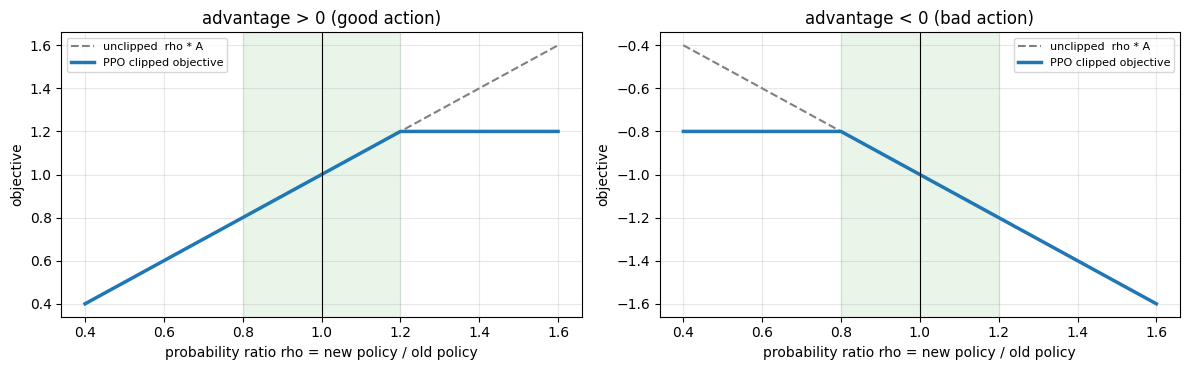

In [6]:
rho = np.linspace(0.4, 1.6, 400); eps_clip = 0.2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, adv, title in zip(axes, [1.0, -1.0], ["advantage > 0 (good action)", "advantage < 0 (bad action)"]):
    unclipped = rho * adv
    clipped = np.minimum(rho * adv, np.clip(rho, 1 - eps_clip, 1 + eps_clip) * adv)
    ax.plot(rho, unclipped, "--", color="gray", label="unclipped  rho * A")
    ax.plot(rho, clipped, color="tab:blue", lw=2.5, label="PPO clipped objective")
    ax.axvline(1, color="k", lw=0.8); ax.axvspan(1 - eps_clip, 1 + eps_clip, color="tab:green", alpha=0.1)
    ax.set_xlabel("probability ratio rho = new policy / old policy"); ax.set_ylabel("objective"); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** With a good action, the objective grows with $\rho$ only up to $1.2$ and is flat beyond. With a bad action, it falls as $\rho$ shrinks only down to $0.8$. Inside the shaded band the gradient is the ordinary policy gradient. Outside it in the "profitable" direction the gradient is exactly zero. That is the whole trick, with no second-order machinery.

Now the experiment. `ppo` uses the advantage $G_t - V(s_t)$ normalised to mean 0 and standard deviation 1 within the batch, 4 epochs on each batch, and the clip above. As an ablation, `ppo_noclip` is identical but without the clip (and without the min), so it just takes 4 plain policy-gradient steps on a stale batch.

In [7]:
def train(method, seed, iters=40, n_ep=16, lr=1e-2):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    pi, v = mlp(2), mlp(1)
    opt = torch.optim.Adam(list(pi.parameters()) + list(v.parameters()), lr=lr)
    curve = []
    for it in range(iters):
        S, A, M = rollout(pi, n_ep, rng)
        St, At, Mt, G = torch.tensor(S), torch.tensor(A), torch.tensor(M), torch.tensor(returns_to_go(M))
        curve.append(M.sum(0).mean())
        with torch.no_grad():
            lp_old = torch.distributions.Categorical(logits=pi(St)).log_prob(At)
        epochs = 4 if method.startswith("ppo") else 1
        for _ in range(epochs):
            lp = torch.distributions.Categorical(logits=pi(St)).log_prob(At)
            V = v(St).squeeze(-1) * 100                       # value scaled so the output stays near 1
            if method == "reinforce":
                adv, target = G, None
            elif method == "baseline":
                adv, target = G - V.detach(), G
            elif method == "actor_critic":
                nxt_alive = torch.tensor(np.concatenate([M[1:], np.zeros((1, n_ep), np.float32)]))
                Vn = torch.cat([V[1:], torch.zeros(1, n_ep)]).detach() * nxt_alive
                target = (1 + GAMMA * Vn)                     # r + gamma V(s'), reward is +1 while alive
                adv = target - V.detach()
            else:                                             # ppo, ppo_noclip
                adv, target = G - V.detach(), G
                adv = (adv - adv[Mt > 0].mean()) / (adv[Mt > 0].std() + 1e-8)
            if method == "ppo":
                ratio = torch.exp(lp - lp_old)
                obj = torch.min(ratio * adv, torch.clamp(ratio, 1 - 0.2, 1 + 0.2) * adv)
            elif method == "ppo_noclip":
                obj = torch.exp(lp - lp_old) * adv
            else:
                obj = lp * adv
            loss = -(obj * Mt).sum() / Mt.sum()
            if target is not None:
                loss = loss + (((target - V) ** 2) * Mt).sum() / Mt.sum() / 1e4
            opt.zero_grad(); loss.backward(); opt.step()
    return np.array(curve), pi

methods = ["reinforce", "baseline", "actor_critic", "ppo", "ppo_noclip"]
t0 = time.time(); results = {}; trained = {}
for m in methods:
    runs = [train(m, seed) for seed in range(3)]
    results[m] = np.array([c for c, _ in runs]); trained[m] = runs[0][1]
    print(f"{m:13s} done in {time.time()-t0:5.1f} s (cumulative)")

reinforce     done in  34.4 s (cumulative)


baseline      done in  54.3 s (cumulative)


actor_critic  done in  68.1 s (cumulative)


ppo           done in 104.0 s (cumulative)


ppo_noclip    done in 133.4 s (cumulative)


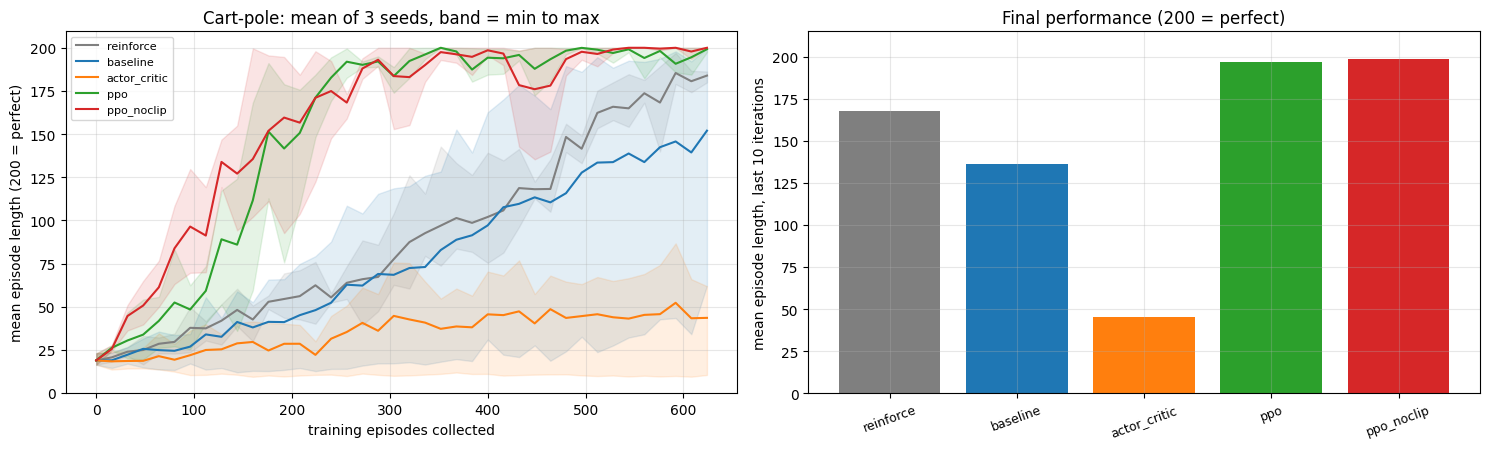

method         episodes to reach mean length 150  final (last 10 iters)  worst seed, final
reinforce                                    512                  167.5              162.9
baseline                                     624                  136.3               35.6
actor_critic                               never                   45.1               10.0
ppo                                          176                  197.0              194.9
ppo_noclip                                   176                  198.4              196.7
(total so far 161 s)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
colors = {"reinforce": "tab:gray", "baseline": "tab:blue", "actor_critic": "tab:orange", "ppo": "tab:green", "ppo_noclip": "tab:red"}
for m in methods:
    mean, lo, hi = results[m].mean(0), results[m].min(0), results[m].max(0)
    x = np.arange(len(mean)) * 16
    axes[0].plot(x, mean, color=colors[m], label=m); axes[0].fill_between(x, lo, hi, color=colors[m], alpha=0.12)
axes[0].set_xlabel("training episodes collected"); axes[0].set_ylabel("mean episode length (200 = perfect)")
axes[0].set_title("Cart-pole: mean of 3 seeds, band = min to max"); axes[0].legend(fontsize=8)

first = {m: next((i * 16 for i, v_ in enumerate(results[m].mean(0)) if v_ >= 150), None) for m in methods}
last = {m: results[m].mean(0)[-10:].mean() for m in methods}
axes[1].bar(range(len(methods)), [last[m] for m in methods], color=[colors[m] for m in methods])
axes[1].set_xticks(range(len(methods))); axes[1].set_xticklabels(methods, rotation=20, fontsize=9)
axes[1].set_ylabel("mean episode length, last 10 iterations"); axes[1].set_ylim(0, 215)
axes[1].set_title("Final performance (200 = perfect)")
plt.tight_layout(); plt.show()

print(f"{'method':13s} {'episodes to reach mean length 150':>34s} {'final (last 10 iters)':>22s} {'worst seed, final':>18s}")
for m in methods:
    worst = results[m][:, -10:].mean(1).min()
    print(f"{m:13s} {str(first[m]) if first[m] is not None else 'never':>34s} {last[m]:22.1f} {worst:18.1f}")
print(f"(total so far {time.time()-T_START:.0f} s)")

In [9]:
t0 = time.time()
torch.manual_seed(1)
pol_mid = trained["baseline"]
var_mid = variance_report(pol_mid, "a policy partly trained by REINFORCE with baseline (seed 0, 40 iterations)")
print(f"({time.time()-t0:.1f} s)")

a policy partly trained by REINFORCE with baseline (seed 0, 40 iterations)
  no baseline    total variance     112483.8   signal-to-noise  0.16
  with baseline  total variance       1103.2   signal-to-noise  0.52
  variance reduced 102.0x
(31.0 s)


**Reading.** Four honest observations, and one of them may surprise you.

1. **Variance.** The baseline reduces the variance of the gradient estimate, and the signal-to-noise ratio rises accordingly (numbers printed above). For the untrained policy the reduction is about 2 times. For the partly trained policy, whose episodes are long and whose returns are large, it is very large (about a hundred times in the run shown, and it varies between runs): the raw return is a big number almost all of which is shared by every action, and the baseline removes that shared part. This is exactly what the theory promises, and it is a *measurement*, not an assumption. (Both estimators are noisy on 60 repetitions; read the orders of magnitude, not the digits.)
2. **But faster learning is not guaranteed.** In this tiny task plain REINFORCE with Adam already learns well, and the learned baseline did *not* make training faster: it was slightly slower to reach a mean length of 150 and one of its three seeds lagged far behind at the end (see the "worst seed" column). Early on the value network is a poor predictor, so it injects its own error into the advantage. With only three seeds this gap is within the seed-to-seed spread, so do not read it as a proven effect either way. Lower gradient variance should help more when the task is harder, the batches are smaller, or the learning rate is larger (exercise 5).
3. **PPO was the strongest here.** `ppo` reached a mean length of 150 in about a third of the episodes of the others and ended close to the maximum with all seeds good. It makes four updates per batch, so it also does more computation per episode: this is a sample-efficiency advantage. The **clip itself mattered little in this easy task**: the no-clip ablation matched it in speed and final score (both close to 200), so here the clip made no measurable difference. Most of PPO's gain here comes from reusing the batch and from normalising the advantage. The clip is insurance that pays off when the learning rate or number of epochs is pushed (exercise 6), not something this toy proves.
4. **The one-step actor-critic was the slowest** and never reached 150. Its critic is bootstrapped from its own estimates, which start wrong, so the advantages are biased early, and one update per batch is little. With a faster critic, several critic steps per batch, or generalised advantage estimation (Schulman et al., 2016, which blends the two estimators) it would do far better. Treat this as "the simplest actor-critic, with no tuning", not as a verdict on actor-critic methods.

**Where the toy differs from the real systems.** Cart-pole has 4 inputs, 2 actions and a 200-step episode, and it is solved with 16 episodes per iteration on a CPU in seconds. Industrial uses (robotics, game-playing, data-centre control) have images or sensor streams as states, continuous actions, episodes of thousands of steps, and need many millions of environment steps and often a simulator that runs on many machines. Our curves are also an average of only three seeds: RL results are notoriously seed-sensitive, and serious papers report many more.

## 6. Reward hacking

An RL agent maximises **the reward you wrote**, not **the outcome you meant**. When the two differ, the agent finds the gap. This is **reward hacking** (also called specification gaming, a case of Goodhart's law: when a measure becomes a target it ceases to be a good measure). It is one of the central problems of AI safety (Amodei et al., 2016; Skalse et al., 2022), and a well-known real example is a boat-racing game agent that learned to circle forever collecting bonus targets instead of finishing the race (Clark and Amodei, 2016).

We reproduce the idea in the smallest possible setting. A **track** of 8 cells, positions 0 to 7. The agent starts at 0 and the intended task is to reach the **goal** at cell 7 (reward $+10$, episode ends). The designer, wanting to "encourage progress", also adds a **checkpoint** at cell 2 that pays $+1$ every time the agent *enters* it. An episode is cut after 60 steps. The agent uses the Q-learning of section 3, with $\gamma = 0.99$.

We compare two reward designs:

* **proxy reward** (badly specified): $+1$ every time the agent enters cell 2;
* **fixed reward**: $+1$ only the *first* time (the agent's state now includes a "checkpoint already collected" flag, so it can tell).

We report two numbers for the greedy trained agent: the **proxy** score it was optimising (checkpoint reward collected) and the **true** objective we actually care about (did it reach the goal?).

reward design                                 reached the goal   checkpoint reward collected
proxy reward (checkpoint pays every time)                   0%                          30.0
fixed reward (checkpoint pays once)                       100%                          11.0

greedy path of the first trained agent under the proxy reward : [0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1] ...
greedy path of the first trained agent under the fixed reward : [0, 1, 2, 3, 4, 5, 6, 7]


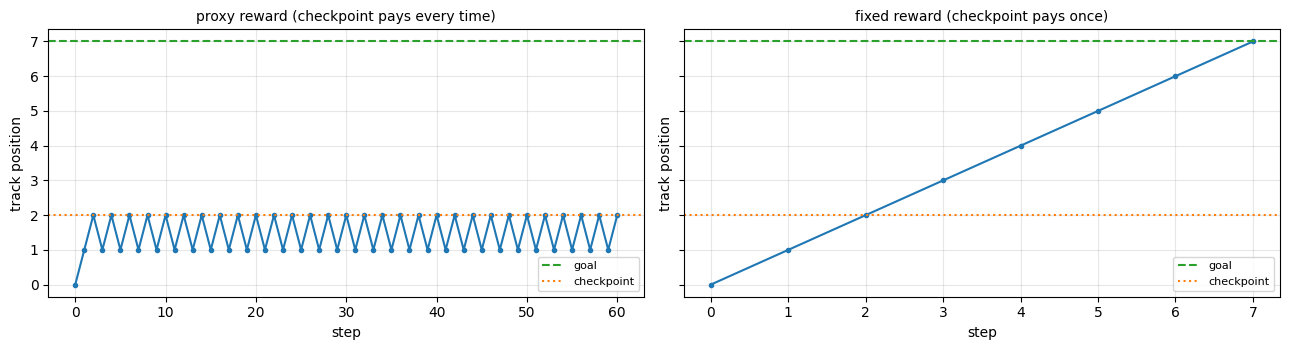

(24.0 s)


In [10]:
TRACK, CHECK, GOAL_POS, HORIZON_H = 8, 2, 7, 60

def track_step(pos, got, a, once):
    pos2 = min(max(pos + (1 if a == 1 else -1), 0), TRACK - 1)
    r, done = 0.0, False
    if pos2 == CHECK and pos != CHECK:
        if not (once and got): r += 1.0
        got = 1
    if pos2 == GOAL_POS: r, done = r + 10.0, True
    return pos2, got, r, done

def train_track(once, seed=0, episodes=1500, alpha=0.1, gamma=0.99, eps=0.2):
    rng = np.random.default_rng(seed); Q = np.zeros((TRACK, 2, 2))
    for ep in range(episodes):
        pos, got = 0, 0
        for t in range(HORIZON_H):
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(Q[pos, got] + rng.uniform(0, 1e-9, 2)))
            pos2, got2, r, done = track_step(pos, got, a, once)
            Q[pos, got, a] += alpha * (r + (0 if done else gamma * Q[pos2, got2].max()) - Q[pos, got, a])
            pos, got = pos2, got2
            if done: break
    return Q

def evaluate_track(Q, once):
    pos, got, proxy, path = 0, 0, 0.0, [0]
    for t in range(HORIZON_H):
        pos, got, r, done = track_step(pos, got, int(np.argmax(Q[pos, got])), once)
        proxy += r; path.append(pos)
        if done: break
    return proxy, pos == GOAL_POS, path

t0 = time.time()
rows = []
for once, name in [(False, "proxy reward (checkpoint pays every time)"), (True, "fixed reward (checkpoint pays once)")]:
    reached, proxies, paths = [], [], []
    for seed in range(5):
        proxy, ok, path = evaluate_track(train_track(once, seed), once)
        reached.append(ok); proxies.append(proxy); paths.append(path)
    rows.append((name, np.mean(reached), np.mean(proxies), paths[0]))

print(f"{'reward design':44s} {'reached the goal':>17s} {'checkpoint reward collected':>29s}")
for name, ok, px, _ in rows:
    print(f"{name:44s} {100*ok:16.0f}% {px:29.1f}")
print("\ngreedy path of the first trained agent under the proxy reward :", rows[0][3][:16], "...")
print("greedy path of the first trained agent under the fixed reward :", rows[1][3])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (name, ok, px, path) in zip(axes, rows):
    ax.plot(path, marker="o", ms=3); ax.axhline(GOAL_POS, color="tab:green", ls="--", label="goal"); ax.axhline(CHECK, color="tab:orange", ls=":", label="checkpoint")
    ax.set_title(name, fontsize=10); ax.set_xlabel("step"); ax.set_ylabel("track position"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"({time.time()-t0:.1f} s)")

**Reading.** Under the proxy reward the trained agent shuttles between cells 1 and 2 and collects the checkpoint bonus again and again, for a total (30 in our run, over 60 steps) three times the 10 points of the goal bonus. It never goes near the goal: **the reward went up, the real objective went to zero**. Nothing is "broken": it is a correct maximiser of an incorrect reward. Under the fixed reward the same algorithm walks straight to the goal in every one of the 5 seeds. Notice that the fix was not a better learner but a better *specification*.

This matters because real reward signals are almost always proxies: a game score, a click rate, a customer rating, a learned reward model. The more capable the optimiser, the more thoroughly it finds the gaps. Practical defences are to reward outcomes rather than easily gamed intermediate events, to limit how far the policy may drift from a trusted one (the idea behind the clipping of section 5, and behind the KL penalty used in language-model training below), to monitor the true objective separately from the optimised reward as we just did, and to inspect behaviour, not only scores.

## 7. Preview: from games to language models

> **This section is a preview, not an experiment.** It runs nothing. It explains how what you just built connects to language models, which module 01 of Neural Networks 1002 builds and measures for real.

A language model such as the GPT of module 10 is, from the RL point of view, a **policy**:

| RL concept | In a language model |
|---|---|
| state $s_t$ | the text so far (prompt plus tokens already written) |
| action $a_t$ | the next **token** |
| policy $\pi_\theta(a \mid s)$ | the model's next-token probability distribution |
| episode | one complete answer |
| reward | a score for the whole answer, often given only at the end |

Pretraining teaches the policy to imitate text. It does not tell it which answers people *prefer*. **RLHF** (reinforcement learning from human feedback, Christiano et al., 2017; Ouyang et al., 2022) adds that signal in three steps: people compare pairs of answers, a **reward model** is trained to predict which one they prefer, and the language model is then trained with **policy gradient to maximise the reward model's score**. In practice the loss is the same family you used in sections 4 and 5: log-probabilities of the sampled tokens weighted by an advantage, usually with the PPO clip, plus a **KL (Kullback-Leibler) penalty** that keeps the new model close to the original one. That penalty is the language-model version of the "do not drift too far" idea behind the PPO clip, and it is also the main defence against the reward hacking of section 6: a reward model is a learned proxy, and a policy that optimises it too hard produces answers the reward model likes and people do not.

**GRPO** (group relative policy optimisation, Shao et al., 2024) simplifies one piece: instead of training a separate critic network to supply the baseline, it samples a **group** of answers to the same prompt and uses the group's average reward as the baseline, normalising each answer's reward against the group. That is the baseline idea of section 4 with a baseline taken from sibling samples.

For agents that use language models as policies that call tools, the [RAG systems course](https://rag-systems.academy.forwardforecasting.eu/) covers the surrounding machinery.

**What is different at real scale.** The policy has billions of weights, the action space is a vocabulary of tens of thousands of tokens, answers are hundreds or thousands of tokens long, and each update needs many sampled answers and a large reward model, on clusters of accelerators. Module 01 of Neural Networks 1002 builds a deliberately tiny version on the small GPT of module 10, so that you can run the whole loop on a laptop and see the same effects (reward going up, KL growing, reward hacking) at toy scale.

## Key takeaways

* RL learns from **scalar, delayed rewards** instead of labelled answers. The ingredients are state, action, reward, policy, return and discount; the data depends on what the agent does, so **exploration** is part of the problem.
* **Bandits** isolate exploration versus exploitation: pure greedy gets stuck, a little exploration pays, directed exploration (UCB) can pay more. Results depend on the problem and the settings.
* **Q-learning** learns a table of action values and works well on small problems. Off-policy Q-learning found the risky shortest path, on-policy SARSA the safe one: *what you learn depends on which policy the values describe*.
* **Policy gradient** adjusts the policy directly: make actions that led to high return more likely. It is unbiased but noisy, and a **baseline** measurably cuts the variance (though that alone did not speed up learning in our small task).
* **PPO** reuses each batch by clipping the probability ratio, so the policy cannot move too far from the one that collected the data. It was the fastest learner in our comparison (though the clip itself mattered little on this easy task), while our untuned one-step actor-critic was the slowest.
* **Reward hacking** is a property of the specification, not of the learner: the same algorithm went from 0 % to 100 % goal-reaching just by fixing the reward.
* Language-model alignment (module 01 of Neural Networks 1002) is this same machinery with tokens as actions and a learned reward model as the reward.

## Exercises

1. In section 2, change the arm values so that rewards have standard deviation 3 instead of 1. Which rule suffers most, and why? Try UCB with $c = 0.5$ and $c = 5$.
2. Add **optimistic initial values** to the bandit (start every $Q$ at 5 with $\varepsilon = 0$). Is exploration still needed?
3. In section 3, set $\varepsilon = 0$ after 400 episodes and compare the final return of Q-learning and SARSA. Then lower $\varepsilon$ gradually during training. Does SARSA approach the shortest path?
4. Change the cliff penalty from $-100$ to $-10$. Do the two algorithms still differ?
5. Run REINFORCE with 4 episodes per iteration instead of 16 and 5 seeds. Does the baseline now make a visible difference in learning speed?
6. In `train`, change the PPO clip from 0.2 to 0.05 and to 0.5, and the number of epochs from 4 to 10. When does it become unstable?
7. Give the actor-critic 5 critic steps per batch, or a learning rate of 0.003 for the actor and 0.03 for the critic. How close does it get to PPO?
8. In section 6, make the checkpoint pay $+0.01$ instead of $+1$. At what value does the agent stop hacking? What does that say about how fragile a reward design can be?

## References

* Sutton, R. S. and Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2nd edition, MIT Press (free online): http://incompleteideas.net/book/the-book-2nd.html
* Auer, P., Cesa-Bianchi, N. and Fischer, P. (2002). Finite-time analysis of the multiarmed bandit problem. *Machine Learning* 47, 235-256: https://doi.org/10.1023/A:1013689704352
* Watkins, C. J. C. H. and Dayan, P. (1992). Q-learning. *Machine Learning* 8, 279-292: https://doi.org/10.1007/BF00992698
* Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature* 518, 529-533: https://doi.org/10.1038/nature14236
* Barto, A. G., Sutton, R. S. and Anderson, C. W. (1983). Neuronlike adaptive elements that can solve difficult learning control problems. *IEEE Transactions on Systems, Man, and Cybernetics* 13(5), 834-846: https://doi.org/10.1109/TSMC.1983.6313077
* Williams, R. J. (1992). Simple statistical gradient-following algorithms for connectionist reinforcement learning (REINFORCE). *Machine Learning* 8, 229-256: https://doi.org/10.1007/BF00992696
* Schulman, J., Moritz, P., Levine, S., Jordan, M. and Abbeel, P. (2016). High-dimensional continuous control using generalized advantage estimation. arXiv:1506.02438: https://arxiv.org/abs/1506.02438
* Schulman, J., Wolski, F., Dhariwal, P., Radford, A. and Klimov, O. (2017). Proximal policy optimization algorithms. arXiv:1707.06347: https://arxiv.org/abs/1707.06347
* Amodei, D. et al. (2016). Concrete problems in AI safety. arXiv:1606.06565: https://arxiv.org/abs/1606.06565
* Skalse, J., Howe, N., Krasheninnikov, D. and Krueger, D. (2022). Defining and characterizing reward hacking. arXiv:2209.13085: https://arxiv.org/abs/2209.13085
* Clark, J. and Amodei, D. (2016). Faulty reward functions in the wild (blog post): https://openai.com/index/faulty-reward-functions/
* Christiano, P. et al. (2017). Deep reinforcement learning from human preferences. arXiv:1706.03741: https://arxiv.org/abs/1706.03741
* Ouyang, L. et al. (2022). Training language models to follow instructions with human feedback. arXiv:2203.02155: https://arxiv.org/abs/2203.02155
* Shao, Z. et al. (2024). DeepSeekMath: pushing the limits of mathematical reasoning in open language models (introduces GRPO). arXiv:2402.03300: https://arxiv.org/abs/2402.03300

In [11]:
print(f"total notebook run time: {time.time() - T_START:.0f} s")

total notebook run time: 216 s
